# Optimización de colas en el control migratorio (M/M/c)

**Investigación de Operaciones · Proyecto final · Ejercicio 4**

El servicio de migración de un aeropuerto opera con **16 ventanillas fijas** en hora pico (costo reportado: 1.120 USD/h).
Se busca el número entero de ventanillas que **minimiza el costo total** (operación + espera) sin que la espera promedio en cola supere **6 minutos**.

| Dato | Símbolo | Valor |
|---|---|---|
| Llegadas (Poisson) | $\lambda$ | 180 pasajeros/h |
| Servicio por ventanilla (exponencial) | $\mu$ | 15 pasajeros/h |
| Costo por ventanilla | $C_s$ | 50 USD/h |
| Costo por pasajero en cola | $C_w$ | 40 USD/h |
| Espera máxima | $W_q^{\max}$ | 6 min = 0,1 h |

**Contenido:** 1) modelo M/M/c · 2) programación entera con PuLP · 3) gráfico · 4) simulación con SimPy · 5) comparación con 16 ventanillas · 6) sensibilidad · 7) demanda por hora · 8) conclusiones.

> Versión interactiva: https://optiqueue-roan.vercel.app

## 0. Preparación

En Google Colab o en un entorno nuevo, instala las dependencias (PuLP 3.x incluye el solver CBC):

In [ ]:
%pip install -q "pulp>=2.8,<4" "simpy>=4.1" "matplotlib>=3.8"

In [1]:
import math
import random
import statistics
from dataclasses import dataclass

import matplotlib.pyplot as plt
import pulp
import simpy

# Parámetros del enunciado
LAMBDA = 180.0   # llegadas (pasajeros/h)
MU = 15.0        # servicio por ventanilla (pasajeros/h)
CS = 50.0        # costo por ventanilla abierta (USD/h)
CW = 40.0        # costo por pasajero en cola (USD/h)
WQ_MAX = 0.1     # espera máxima en cola (h) = 6 min
X_ACTUAL = 16    # ventanillas actuales
COSTO_REPORTADO = 1120.0  # USD/h con 16 ventanillas
HORAS_PICO_DIA, DIAS_ANIO = 16, 365

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("PuLP", pulp.__version__, "· SimPy", simpy.__version__)

PuLP 3.3.2 · SimPy 4.1.2


## 1. Modelo analítico M/M/c (Erlang C)

Con $x$ ventanillas en paralelo:

$$a = \frac{\lambda}{\mu}, \qquad \rho = \frac{a}{x} < 1$$

$$P_0 = \left[\sum_{n=0}^{x-1} \frac{a^n}{n!} + \frac{a^x}{x!\,(1-\rho)}\right]^{-1}, \qquad
P_w = \frac{a^x}{x!\,(1-\rho)}\,P_0$$

$$L_q = P_w\,\frac{\rho}{1-\rho}, \qquad W_q = \frac{L_q}{\lambda} \;\text{(ley de Little)}, \qquad CT(x) = C_s\,x + C_w\,L_q(x)$$

In [2]:
@dataclass(frozen=True)
class Metricas:
    c: int
    rho: float
    p0: float
    pw: float
    lq: float
    wq: float  # horas
    cs: float = CS
    cw: float = CW

    @property
    def costo(self) -> float:
        return self.cs * self.c + self.cw * self.lq


def mmc(c, lam=LAMBDA, mu=MU, cs=CS, cw=CW):
    """Indicadores de estado estable de una cola M/M/c (None si es inestable)."""
    a = lam / mu
    rho = a / c
    if rho >= 1:
        return None
    suma = sum(a**n / math.factorial(n) for n in range(c))
    cola = a**c / (math.factorial(c) * (1 - rho))
    p0 = 1 / (suma + cola)
    pw = cola * p0
    lq = pw * rho / (1 - rho)
    return Metricas(c, rho, p0, pw, lq, lq / lam, cs, cw)


m = mmc(15)
print(f"x = 15: a = {LAMBDA / MU:.0f} erlangs, ρ = {m.rho:.2%}, P0 = {m.p0:.3e}, Pw = {m.pw:.4f}")
print(f"        Lq = {m.lq:.4f} pasajeros, Wq = {m.wq:.5f} h = {m.wq * 60:.3f} min = {m.wq * 3600:.1f} s")
print(f"        CT = {CS:.0f}·15 + {CW:.0f}·{m.lq:.4f} = {m.costo:.2f} USD/h")

x = 15: a = 12 erlangs, ρ = 80.00%, P0 = 5.418e-06, Pw = 0.3192
        Lq = 1.2768 pasajeros, Wq = 0.00709 h = 0.426 min = 25.5 s
        CT = 50·15 + 40·1.2768 = 801.07 USD/h


In [3]:
print(f"{'x':>3} {'ρ':>7} {'Pw':>7} {'Lq':>8} {'Wq (min)':>9} {'CT (USD/h)':>11}  estado")
for c in range(12, 21):
    m = mmc(c)
    if m is None:
        print(f"{c:>3} {'≥100%':>7} {'—':>7} {'∞':>8} {'∞':>9} {'∞':>11}  inestable")
        continue
    estado = "cumple" if m.wq <= WQ_MAX else "NO cumple"
    print(f"{c:>3} {m.rho:>7.1%} {m.pw:>7.4f} {m.lq:>8.3f} {m.wq * 60:>9.3f} {m.costo:>11.2f}  {estado}")

  x       ρ      Pw       Lq  Wq (min)  CT (USD/h)  estado
 12   ≥100%       —        ∞         ∞           ∞  inestable
 13   92.3%  0.7044    8.453     2.818      988.11  cumple
 14   85.7%  0.4817    2.890     0.963      815.61  cumple
 15   80.0%  0.3192    1.277     0.426      801.07  cumple
 16   75.0%  0.2046    0.614     0.205      824.55  cumple
 17   70.6%  0.1266    0.304     0.101      862.16  cumple
 18   66.7%  0.0756    0.151     0.050      906.05  cumple
 19   63.2%  0.0435    0.075     0.025      952.98  cumple
 20   60.0%  0.0241    0.036     0.012     1001.45  cumple


## 2. Programación entera con PuLP

Variables: $x \in \mathbb{Z}$ (ventanillas) e $y \ge 0$ (costo, USD/h). Como $CT(x)$ es **convexa**, se representa exactamente en
los enteros con las secantes entre puntos consecutivos:

$$\min\; y \quad \text{s.a.}\quad y \ge CT(k) + [CT(k+1) - CT(k)]\,(x-k)\;\;\forall k, \qquad W_q(x) \le 0{,}1 \iff x \ge x_{SLA}$$

In [4]:
def resolver(lam=LAMBDA, mu=MU, cs=CS, cw=CW, wq_max=WQ_MAX, x_max=60, verbose=False):
    """Modelo entero con cortes secantes. Devuelve (estado, x*, y*)."""
    x_min = math.floor(lam / mu) + 1
    candidatos = range(x_min, x_max + 1)
    costo = {c: mmc(c, lam, mu, cs, cw).costo for c in candidatos}
    x_sla = min(c for c in candidatos if mmc(c, lam, mu, cs, cw).wq <= wq_max)

    prob = pulp.LpProblem("Ventanillas_Migracion", pulp.LpMinimize)
    x = pulp.LpVariable("x", lowBound=x_min, upBound=x_max, cat=pulp.LpInteger)
    y = pulp.LpVariable("y", lowBound=0)
    prob += y, "costo_total"
    for k in candidatos[:-1]:
        prob += y >= costo[k] + (costo[k + 1] - costo[k]) * (x - k), f"secante_{k}"
    prob += x >= x_sla, "nivel_de_servicio"
    prob.solve(pulp.PULP_CBC_CMD(msg=False))
    if verbose:
        print(f"Restricciones: {len(prob.constraints)} (secantes + nivel de servicio); x_SLA = {x_sla}")
    return pulp.LpStatus[prob.status], round(x.value()), float(y.value())


estado, x_opt, y_opt = resolver(x_max=20, verbose=True)
print(f"Estado: {estado}  →  x* = {x_opt} ventanillas, y* = {y_opt:.2f} USD/h")

Restricciones: 8 (secantes + nivel de servicio); x_SLA = 13
Estado: Optimal  →  x* = 15 ventanillas, y* = 801.07 USD/h


## 3. Gráfico: costo total frente a tiempo de espera

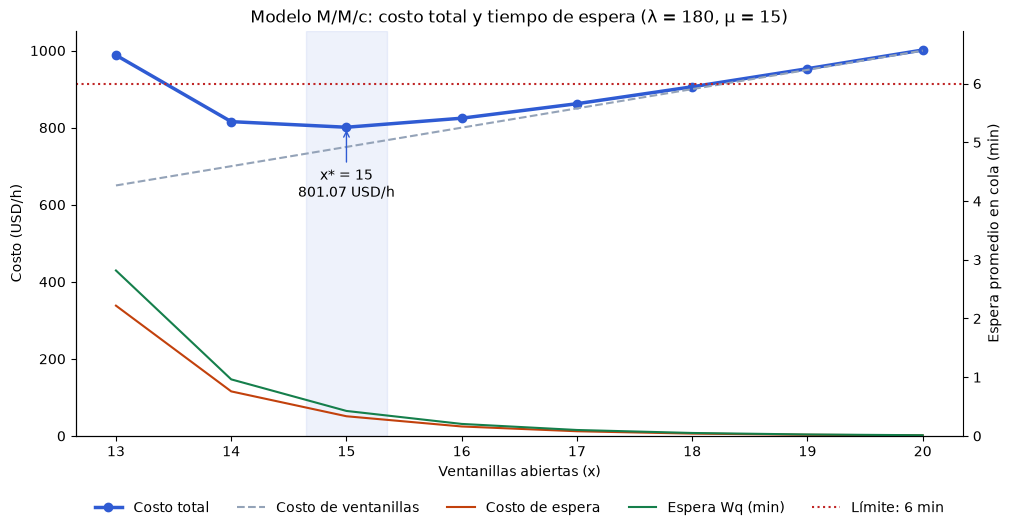

In [5]:
xs = list(range(13, 21))
ms = [mmc(c) for c in xs]
fig, ax = plt.subplots(figsize=(10, 5.2), constrained_layout=True)
ax.plot(xs, [m.costo for m in ms], "o-", lw=2.5, color="#2f5bd3", label="Costo total")
ax.plot(xs, [CS * c for c in xs], "--", color="#94a3b8", label="Costo de ventanillas")
ax.plot(xs, [CW * m.lq for m in ms], color="#c2410c", label="Costo de espera")
ax.axvspan(x_opt - 0.35, x_opt + 0.35, color="#2f5bd3", alpha=0.08)
ax.annotate(f"x* = {x_opt}\n{y_opt:.2f} USD/h", xy=(x_opt, y_opt), xytext=(0, -50), textcoords="offset points",
            ha="center", arrowprops={"arrowstyle": "->", "color": "#2f5bd3"})
ax.set(xlabel="Ventanillas abiertas (x)", ylabel="Costo (USD/h)", ylim=(0, None))
ax2 = ax.twinx()
ax2.plot(xs, [m.wq * 60 for m in ms], color="#157f4b", label="Espera Wq (min)")
ax2.axhline(WQ_MAX * 60, color="#c02626", ls=":", label="Límite: 6 min")
ax2.set(ylim=(0, WQ_MAX * 60 * 1.15), ylabel="Espera promedio en cola (min)")
ax2.spines["right"].set_visible(True)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=5, frameon=False)
ax.set_title("Modelo M/M/c: costo total y tiempo de espera (λ = 180, μ = 15)")
plt.show()

## 4. Validación con simulación de eventos discretos (SimPy)

Llegadas de Poisson, servicio exponencial, cola FIFO única. Se descartan los primeros 15 minutos (la sala arranca vacía) y se
promedian 30 réplicas independientes de 8 horas.

In [6]:
CALENTAMIENTO = 0.25  # h
Z_95 = 1.96


def replica(x, horas, semilla, lam=LAMBDA, mu=MU):
    rng = random.Random(semilla)
    env = simpy.Environment()
    ventanillas = simpy.Resource(env, capacity=x)
    esperas = []

    def pasajero():
        llegada = env.now
        with ventanillas.request() as turno:
            yield turno
            if llegada >= CALENTAMIENTO:
                esperas.append(env.now - llegada)
            yield env.timeout(rng.expovariate(mu))

    def llegadas():
        while True:
            yield env.timeout(rng.expovariate(lam))
            env.process(pasajero())

    env.process(llegadas())
    env.run(until=CALENTAMIENTO + horas)
    return statistics.fmean(esperas)


def simular(x, horas=8.0, replicas=30, semilla=2026):
    wq = [replica(x, horas, semilla + i) for i in range(replicas)]
    media = statistics.fmean(wq)
    semiancho = Z_95 * statistics.stdev(wq) / replicas**0.5
    return media * 60, semiancho * 60, CS * x + CW * LAMBDA * media


print(f"{'x':>3} {'Wq simulada (min)':>22} {'Wq teórica':>11} {'¿IC contiene?':>14} {'CT sim.':>9}")
for x in (14, 15, 16):
    wq, ic, ct = simular(x)
    teo = mmc(x).wq * 60
    print(f"{x:>3} {wq:>13.3f} ± {ic:<6.3f} {teo:>11.3f} {'sí' if abs(wq - teo) <= ic else 'no':>14} {ct:>9.2f}")

  x      Wq simulada (min)  Wq teórica  ¿IC contiene?   CT sim.
 14         0.868 ± 0.175        0.963             sí    804.19
 15         0.411 ± 0.061        0.426             sí    799.37
 16         0.228 ± 0.055        0.205             sí    827.36


## 5. Comparación con las 16 ventanillas actuales (pregunta 2)

In [7]:
opt, act = mmc(x_opt), mmc(X_ACTUAL)
ahorro_h = COSTO_REPORTADO - opt.costo
print(f"Costo con {x_opt}: {opt.costo:.2f} USD/h   |   reportado con 16: {COSTO_REPORTADO:.2f} USD/h")
print(f"Ahorro: {ahorro_h:.2f} USD/h ({ahorro_h / COSTO_REPORTADO:.2%})  →  {ahorro_h * HORAS_PICO_DIA * DIAS_ANIO:,.0f} USD/año")
print(f"Espera: {act.wq * 3600:.1f} s con 16  →  {opt.wq * 3600:.1f} s con {x_opt} (+{(opt.wq - act.wq) * 3600:.1f} s)")
print(f"Costo teórico del modelo con 16: {act.costo:.2f} USD/h (ahorro teórico {act.costo - opt.costo:.2f} USD/h)")

Costo con 15: 801.07 USD/h   |   reportado con 16: 1120.00 USD/h
Ahorro: 318.93 USD/h (28.48%)  →  1,862,548 USD/año
Espera: 12.3 s con 16  →  25.5 s con 15 (+13.3 s)
Costo teórico del modelo con 16: 824.55 USD/h (ahorro teórico 23.48 USD/h)


## 6. Análisis de sensibilidad

¿En qué rango de cada parámetro sigue siendo óptimo $x^* = 15$? Para los costos el umbral es exacto por análisis marginal:
conviene pasar de 15 a 16 cuando $C_w\,[L_q(15) - L_q(16)] > C_s$.

In [8]:
def x_optimo(**cambios):
    p = dict(lam=LAMBDA, mu=MU, cs=CS, cw=CW, wq_max=WQ_MAX) | cambios
    mejor = None
    for c in range(1, 100):
        m = mmc(c, p["lam"], p["mu"], p["cs"], p["cw"])
        if m and m.wq <= p["wq_max"] and (mejor is None or m.costo < mejor.costo):
            mejor = m
    return mejor.c


def rango(param, lo, hi, x0=15, pasos=60):
    """Extremos del intervalo [lo, hi] donde x*(param) = x0, por bisección."""
    base = {"mu": MU, "cw": CW, "cs": CS, "lam": LAMBDA}[param]
    def borde(desde, hasta):
        if x_optimo(**{param: hasta}) == x0:
            return None, None
        ok, mal = desde, hasta
        for _ in range(pasos):
            mid = (ok + mal) / 2
            ok, mal = (mid, mal) if x_optimo(**{param: mid}) == x0 else (ok, mid)
        return ok, x_optimo(**{param: mal})
    return borde(base, lo), borde(base, hi)


lq = {c: mmc(c).lq for c in (14, 15, 16)}
print(f"Umbral exacto Cw (15→16): Cs / (Lq15 − Lq16) = {CS / (lq[15] - lq[16]):.2f} USD/h")
print(f"Umbral exacto Cw (15→14): Cs / (Lq14 − Lq15) = {CS / (lq[14] - lq[15]):.2f} USD/h\n")

nombres = {"mu": "μ (pas/h)", "cw": "Cw (USD/h)", "cs": "Cs (USD/h)", "lam": "λ (pas/h)"}
limites = {"mu": (10, 24), "cw": (5, 160), "cs": (10, 150), "lam": (100, 300)}
print(f"{'Parámetro':<12} {'x*=15 entre':>20} {'debajo':>7} {'encima':>7}")
for p, (lo, hi) in limites.items():
    (a, xa), (b, xb) = rango(p, lo, hi)
    print(f"{nombres[p]:<12} {a:>9.2f} – {b:<8.2f} {xa:>7} {xb:>7}")

Umbral exacto Cw (15→16): Cs / (Lq15 − Lq16) = 75.41 USD/h
Umbral exacto Cw (15→14): Cs / (Lq14 − Lq15) = 30.99 USD/h

Parámetro             x*=15 entre  debajo  encima
μ (pas/h)        14.21 – 15.30         16      14
Cw (USD/h)       30.99 – 75.41         14      16
Cs (USD/h)       26.52 – 64.54         16      14
λ (pas/h)       176.43 – 189.95        14      16


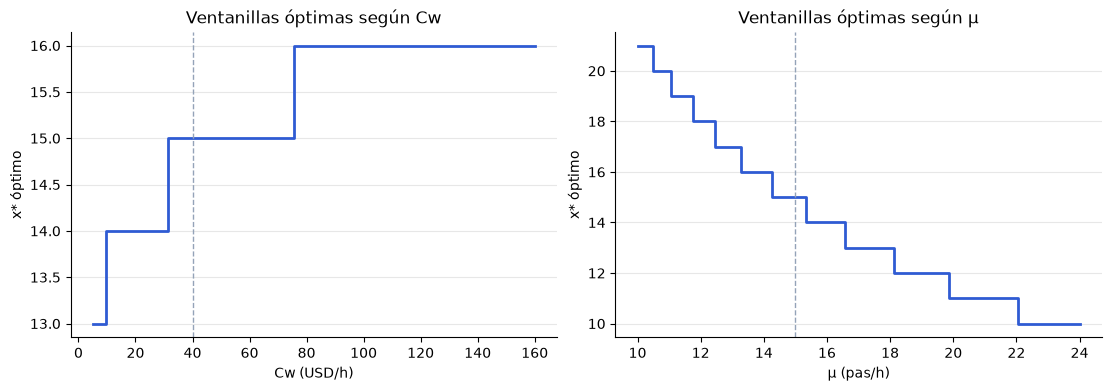

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8), constrained_layout=True)
for ax, (p, (lo, hi), base) in zip(axs, [("cw", (5, 160), CW), ("mu", (10, 24), MU)]):
    vs = [lo + (hi - lo) * i / 200 for i in range(201)]
    ax.step(vs, [x_optimo(**{p: v}) for v in vs], where="post", color="#2f5bd3", lw=2)
    ax.axvline(base, color="#94a3b8", ls="--", lw=1)
    ax.set(xlabel=nombres[p], ylabel="x* óptimo", title=f"Ventanillas óptimas según {nombres[p].split()[0]}")
    ax.grid(axis="y", alpha=0.3)
plt.show()

## 7. Extensión: demanda por hora del día

El enunciado modela la hora pico (λ = 180). Con un perfil **ilustrativo** de 24 horas, cada hora se resuelve como un M/M/c
estacionario independiente (método SIPP) y se compara con mantener 15 ventanillas todo el día.

In [10]:
PERFIL = [40, 30, 25, 20, 35, 70, 120, 160, 180, 170, 140, 120,
          110, 115, 125, 135, 150, 165, 180, 175, 155, 130, 95, 60]

plan = [x_optimo(lam=lam) for lam in PERFIL]
costo_plan = sum(mmc(x, lam).costo for x, lam in zip(plan, PERFIL))
costo_fijo = sum(mmc(15, lam).costo for lam in PERFIL)

print("Hora:  " + " ".join(f"{h:>3}" for h in range(24)))
print("λ:     " + " ".join(f"{l:>3}" for l in PERFIL))
print("x*:    " + " ".join(f"{x:>3}" for x in plan))
print(f"\nVentanilla-horas/día: plan {sum(plan)}  vs. fijo {15 * 24}")
print(f"Costo/día: plan {costo_plan:,.0f} USD  vs. 15 fijas {costo_fijo:,.0f} USD")
print(f"Ahorro: {costo_fijo - costo_plan:,.0f} USD/día ({1 - costo_plan / costo_fijo:.1%}) ≈ {(costo_fijo - costo_plan) * 365:,.0f} USD/año")

Hora:    0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17  18  19  20  21  22  23
λ:      40  30  25  20  35  70 120 160 180 170 140 120 110 115 125 135 150 165 180 175 155 130  95  60
x*:      4   3   3   2   4   6  10  13  15  14  12  10  10  10  11  11  13  14  15  14  13  11   8   6

Ventanilla-horas/día: plan 232  vs. fijo 360
Costo/día: plan 12,768 USD  vs. 15 fijas 18,237 USD
Ahorro: 5,469 USD/día (30.0%) ≈ 1,996,232 USD/año


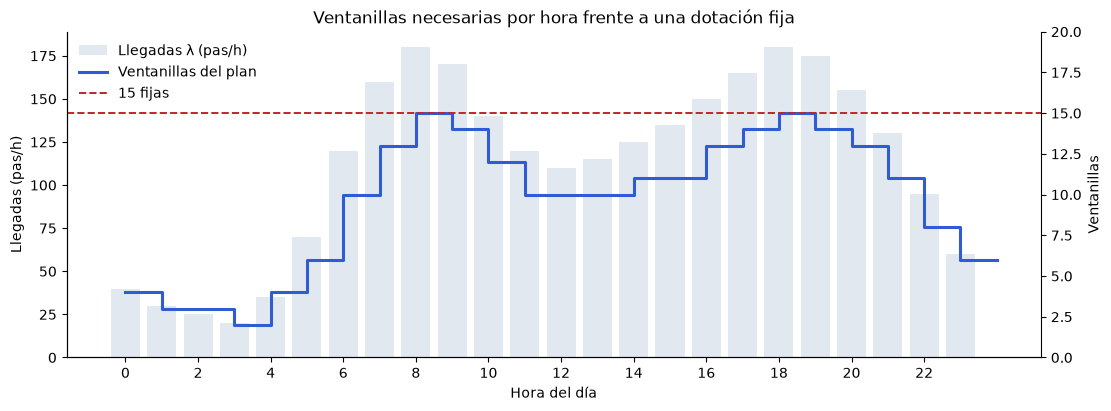

In [11]:
fig, ax = plt.subplots(figsize=(11, 4), constrained_layout=True)
ax.bar(range(24), PERFIL, color="#e2e8f0", label="Llegadas λ (pas/h)")
ax.set(xlabel="Hora del día", ylabel="Llegadas (pas/h)", xticks=range(0, 24, 2))
ax2 = ax.twinx()
ax2.step(range(25), plan + plan[-1:], where="post", color="#2f5bd3", lw=2.2, label="Ventanillas del plan")
ax2.axhline(15, color="#c02626", ls="--", lw=1.4, label="15 fijas")
ax2.set(ylabel="Ventanillas", ylim=(0, 20))
ax2.spines["right"].set_visible(True)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper left", frameon=False)
ax.set_title("Ventanillas necesarias por hora frente a una dotación fija")
plt.show()

## 8. Conclusiones

1. **Pregunta 1:** el óptimo es **15 ventanillas**, con un costo de **801,07 USD/h**, utilización del 80 % y espera promedio de
   25,5 s (muy por debajo de 6 min). El modelo analítico, PuLP y la simulación coinciden.
2. **Pregunta 2:** frente a las 16 ventanillas (1.120 USD/h reportados) se ahorran **318,93 USD/h (−28,5 %)**, unos
   **1,86 millones USD/año**, y la espera solo sube 13 s.
3. **Sensibilidad:** la solución es robusta frente a los costos (Cw entre ~31 y ~75 USD/h) pero sensible a μ y λ: si cada
   ventanilla atiende menos de ~14,2 pas/h o la demanda supera ~190 pas/h conviene abrir 16.
4. **Demanda por hora:** ajustar las ventanillas por franja reduce el costo diario alrededor de un 30 % frente a 15 fijas.